In [ ]:
#%%
import math
import numpy as np
import inspect
import importlib

import scipy.interpolate

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.pyplot as plt

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 16

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.offline import plot
pio.renderers.default = "svg"

import sys
import os
parent_directory = os.path.dirname(os.getcwd())
sys.path.append(parent_directory)
#parent_directory = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
#sys.path.append(parent_directory)
 
import IoT_node_models 
from IoT_node_models import *

path_to_save_svg = "Saved_Data"



In [38]:

#importlib.reload(IoT_node_models)
#from IoT_node_models import *

In [29]:
footprintStructure = FootprintStructure(("GWP", "Money"), units=("$kgCO_2 eq.$", "EUR"))


In [30]:
# Footprint factors: GWP is (low, mid, high), Money is a fixed value
this_LDO = LDO(name = "Node LDO", category = "Power_supply", v_out = 3.3, i_q = 1e-3, v_in = 3.3, component_list = component_List_3V3,
                factors = footprintStructure.vector(GWP=(0.0446, 0.132, 0.1751), Money=0.228))     # XC6206 : 0.228 + Diode and Transistor?

this_Batt= Battery(name = "Node Batt.", category = "Battery", v = 3.3, capacity_mAh = 1800, i = 0, selfdischarge_p_year = 5)


In [31]:
this_hw = Hardware(name= "IoT Node",footprintStructure=footprintStructure, categories=DEFAULT_CATEGORIES)
for comp in component_List_3V3:
    this_hw.add(comp)
this_hw.add(this_LDO)
this_hw.add(this_Batt)

In [32]:

this_profile= LoRa_Profile("Profile", this_hw,  RX_state=radio_state_RX_3V3,TX_state=radio_state_TX_3V3,
                    P_TX= PTX_PABOOST_3V3, I_TX=I_PABoost_3V3 ) 
             

In [33]:

this_task_tx0 = this_profile.create_task_tx(name="TX-0", Ptx = 17,SF=7 ,Coding=1,Header=True,DE = 0,BW = 125e3, Payload = 50, TX_rate=24*1)
this_task_rx0 = this_profile.create_task_rx(name="RX-0", RX_rate=2, RX_duration=0.250 )

this_profile.add_task(task_TPHG_3V3,24*12)

In [34]:

this_node = Node_description(name="My_node",hardware=this_hw,profile=this_profile)


In [35]:
def PL_model(d):
    return path_loss_PLd0(d=d, PLd0=94.40,d0=1, n=2.03)

this_task_tx0.set_Path_loss_model(PL_model)

-------------------------------------------------
            Tasks summary                        
-------------------------------------------------
Task name            : TX-0           RX-0           TPHG meas.     Sleep          
Times/day    [1/d]   : 24             2              288            1              
Tot. durat.  [s]     : 51.3147        0.5000         628.7988       0.0000         
Tot. en./d   [mJ]    : 20159.7449     18.6120        23482.7893     985.5394       
Node en./d   [mJ]    : 44646.6856      
-------------------------------------------------
-----------------------------------------------------------------
                        Module summary                           
-----------------------------------------------------------------
Component    State        Active [s]   Energy [mJ]  Av. Cur.[uA]  
Apollo3                   615.3607     1934.0443    6.7832641     
     -       Active       615.3607     1163.5856    
     -       Sleep        85784.6393   

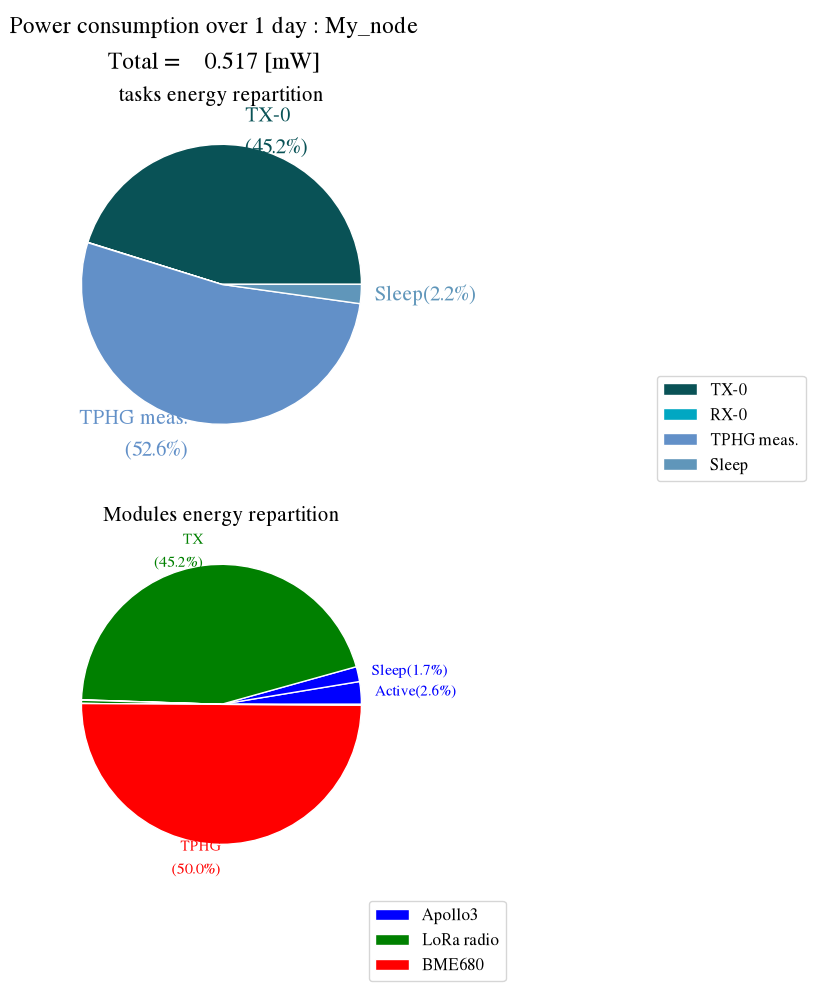

In [36]:
this_task_tx0.set_distance( d= 1500)
this_node.compute()
this_node.print_tasks()
this_node.print_components()
this_node.plot_power()

Category       GWP [$kgCO_2 eq.$]      Money [EUR]
-------------  ----------------------  -----------
Casing         0                       0          
Connectivity   0                       0          
EoL            0                       0          
Memory         0                       0          
Others         0                       0          
PCB            0                       0          
Power_supply   [0.0446, 0.132, 0.175]  0.228      
Processing     0                       0          
Sensing        0                       0          
UI             0                       0          
Battery        0                       0          
Uncategorized  0                       0          
-------------  ----------------------  -----------
Total          [0.0446, 0.132, 0.175]  0.228      


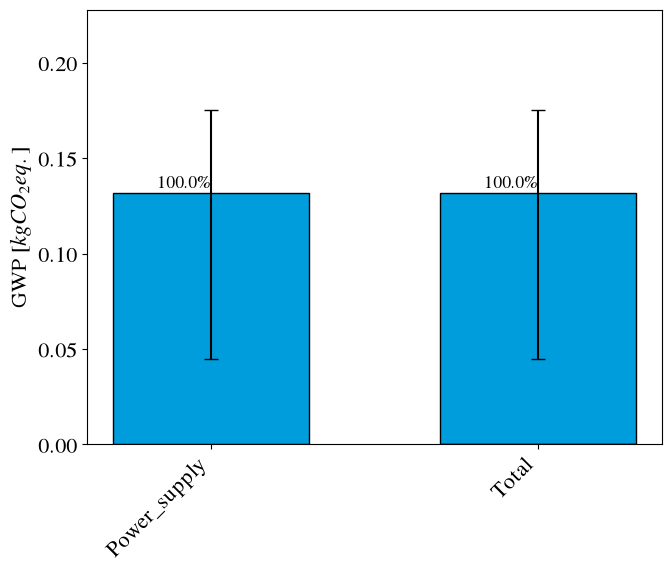

In [37]:
this_hw.compute_footprint()
this_hw.report_footprint()
this_hw.plot_footprint(label="GWP")

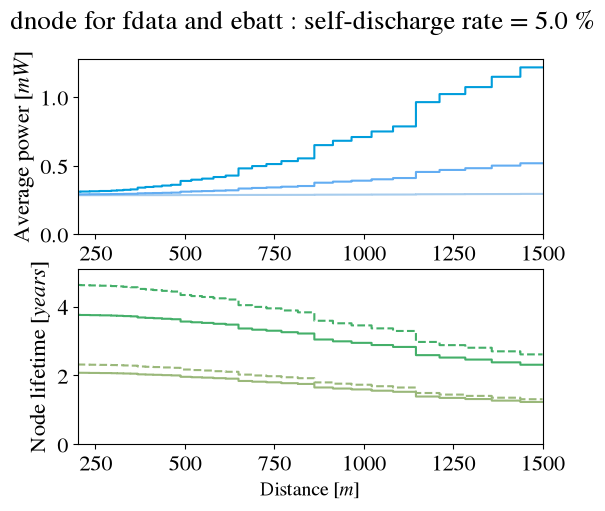

In [10]:
#sweep_dnode(Node=this_node, 
#            dmax=1500, 
#            d_step=3 ,
#            nAA = [1,3],
#            Task_tx=this_task_tx0, 
#            PL_model=PL_model, 
#            filename =None,
#            figsize=(6,5))
#
#sweep_task_rate(Node=this_node, 
#            fmax=24*60, 
#            f_step=1, 
#            Task= task_TPHG_3V3,
#            nAA = [1,3,5],
#            filename =None,
#            figsize=(6,5)) 
#
#sweep_fdata(Node=this_node, 
#        fmax=24*10, 
#        f_step=1, 
#        Task_tx = this_task_tx0,
#        d = 1000,
#        nAA = [1,3,5],
#        filename =None,
#        figsize=(6,5)) 

sweep_dnode_fdata_Ebatt( Node=this_node,
                            dmin = 200, 
                            dmax=1500, 
                            d_step=2,
                            f_batt = 24,
                            fdata = [1,24, 24*4],
                            nAA = [1,2], 
                            Task_tx = this_task_tx0, 
                            PL_model=PL_model, 
                            filename =None,
                            figsize=(6,5)) 
     